In [ ]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from pandas import DataFrame
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
CLUSTER_INFO = f'{DATA_DIR}/cluster_info.csv'
FRAC_DF = f'{DATA_DIR}/frac_df.csv'
SIGMATRIX_GLOB = f'{DATA_DIR}/sigmat_select/*.txt'

# Output files
REFERENCE_COUNTS_OUT = f'{RESULTS_DIR}/reference_counts.csv'
TRANSCELL_INPUT_DIR = f'{RESULTS_DIR}/transcell_input'
os.makedirs(RESULTS_DIR, exist_ok=True)

In [2]:
warnings.filterwarnings("ignore")

In [3]:
pat_info = pd.read_csv(CLUSTER_INFO, index_col=0)
frac_df = pd.read_csv(FRAC_DF, index_col=0)

type_X = 'X..Blasts.in.BM'

In [4]:
progen_df1 = frac_df*100
progen_df1.index = [int(i.split('_')[0]) for i in progen_df1.index]
progen_df2 = DataFrame(pat_info[type_X]).dropna()

ind = list(set(progen_df1.index) & set(progen_df2.index))
progen_df1 = progen_df1.loc[ind]
progen_df2 = progen_df2.loc[ind]

In [5]:
list_pdf = []

for i in progen_df1.columns:
    pdf = DataFrame(progen_df1[i] - progen_df2[type_X], columns=[i])
    list_pdf.append(pdf)

dist_df = pd.concat(list_pdf, axis=1)

In [6]:
dist_df = np.abs(dist_df.T)

In [7]:
f, ax = plt.subplots(figsize=(35, 30), dpi=300)
ax = sns.heatmap(dist_df, cmap="Greens_r", vmax=40)
plt.yticks(rotation=0) 

plt.show()

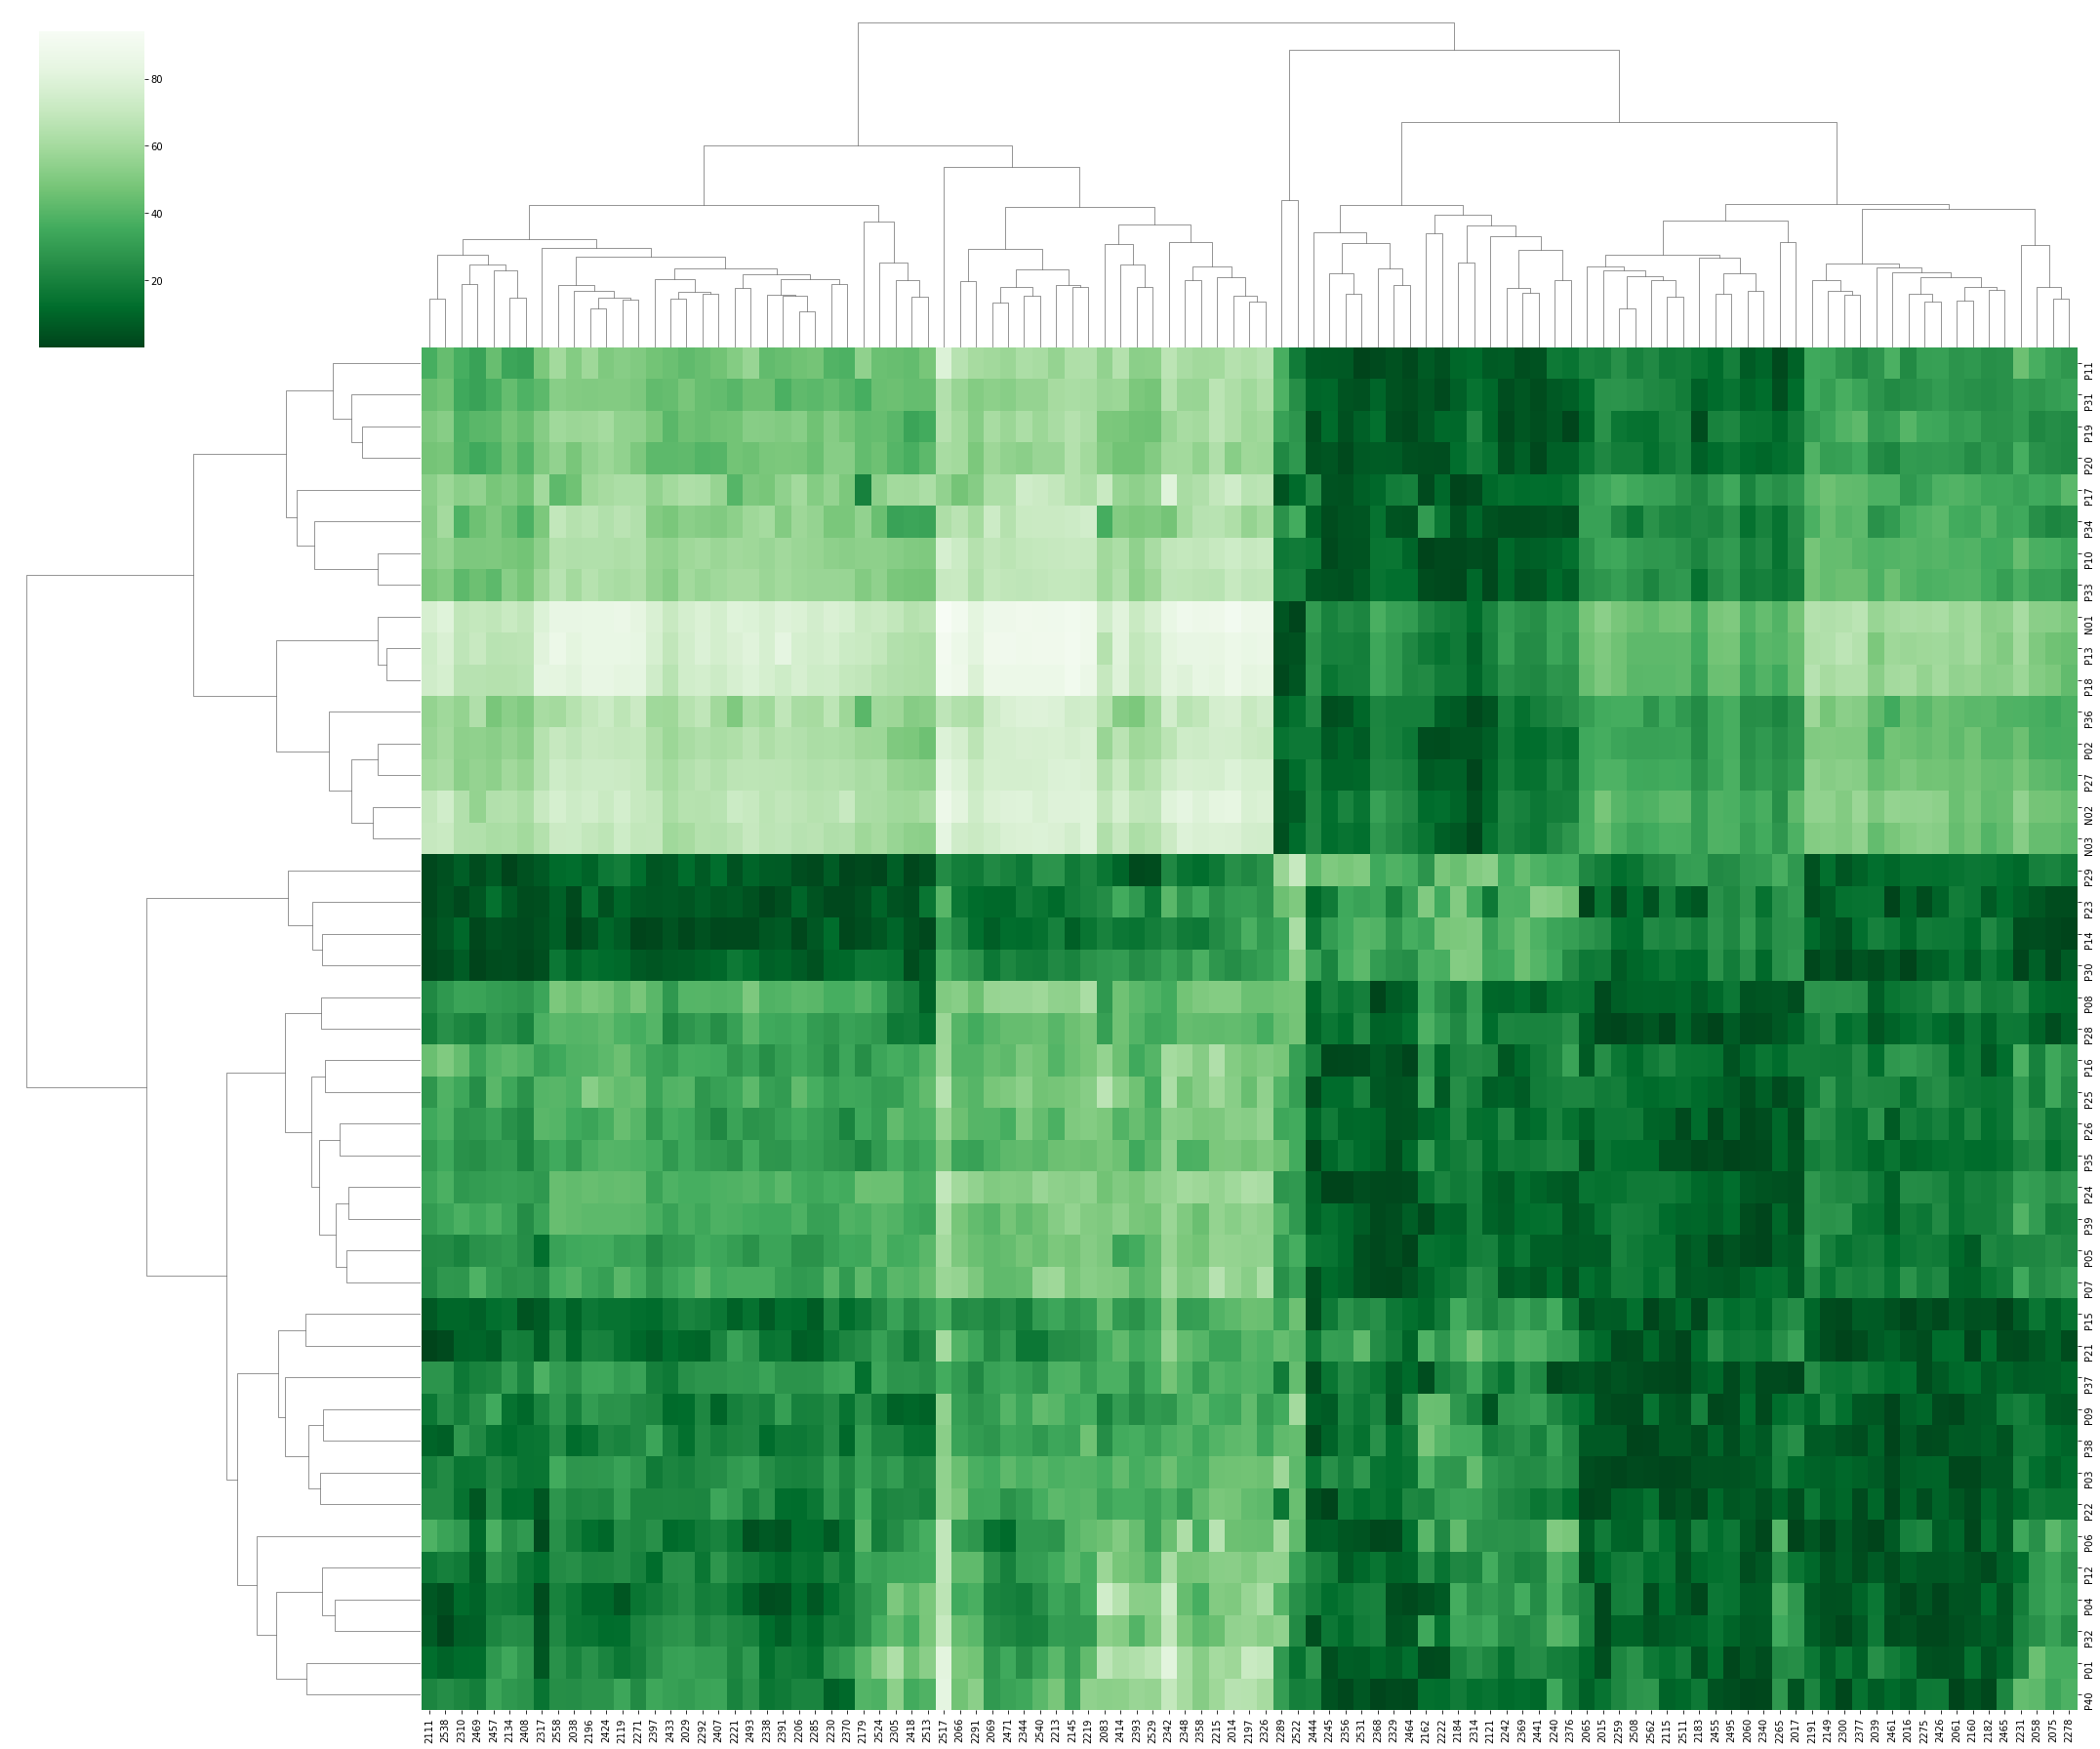

In [14]:
sns.clustermap(dist_df, cmap='Greens_r', figsize=(30,25))

In [8]:
d_p = dist_df.idxmin(axis=0)

In [9]:
dfs = progen_df1

list_val = []
for i in range(len(d_p.index)):
    val = dfs.loc[d_p.index[i]][d_p.iloc[i]]
    list_val.append(DataFrame([val], index=[d_p.index[i]], columns=['Best']))

best_df = pd.concat(list_val)

In [10]:
test_df = pd.concat([best_df, progen_df2], axis=1)

spearman = stats.spearmanr(test_df[test_df.columns[0]].values, test_df[test_df.columns[1]].values)
pearson = stats.pearsonr(test_df[test_df.columns[0]].values, test_df[test_df.columns[1]].values)

print(spearman)
print(pearson)

SpearmanrResult(correlation=0.9143678135316613, pvalue=1.8932702216674045e-41)
(0.9659794539958472, 3.909377795423208e-61)


In [157]:
d_p.value_counts().to_csv(REFERENCE_COUNTS_OUT)

In [197]:
path = SIGMATRIX_GLOB
filenames = glob.glob(path)

In [235]:
list_dfb = []

for f in filenames:
    dfa = pd.read_csv(f, sep='\t', index_col=0).dropna()

    nom = f.split('_')[-5]
    indi = list(d_p[d_p == nom].index)

    col_list = []
    for k in indi:
        next_col = [col for col in dfa.columns if str(k) in col][0]
        col_list.append(next_col)

    dfb = dfa[col_list]
    list_dfb.append(dfb)

In [263]:
mixed_ref = pd.concat(list_dfb, axis=1).fillna(1).reset_index()
mixed_ref = mixed_ref.rename(columns={'GeneSymbol':'genes'}).set_index('genes')

In [264]:
proj = 'mix'

ref1 = mixed_ref.filter(regex='_Ref1').sort_index(axis=1)
ref2 = mixed_ref.filter(regex='_Ref2').sort_index(axis=1)
ref3 = mixed_ref.filter(regex='_Ref3').sort_index(axis=1)
cr = mixed_ref.filter(regex='_CR').sort_index(axis=1)
list_data = [ref1, ref2, ref3, cr]

In [266]:
for k in range(len(list_data)):
    for i in range(int(len(cr.columns)/6 + 1)):
        df = list_data[k][list_data[k].columns[6*i:(6*i + 6)]]
        if len(df.columns) > 0:
            path = f'{TRANSCELL_INPUT_DIR}/{proj.upper()}/'
            exist = os.path.exists(path)
            if not exist:
                os.makedirs(path)
                print("The new directory is created!")
            df.to_csv(path + f'{proj}_{k}_{i}.csv')
            with open(f'{TRANSCELL_INPUT_DIR}/sample_names.txt', 'a') as f:
                f.write(f'{proj}_{k}_{i}.csv')
                f.write('\n')